# Subhalo movies for every regime

Movies of the host-centric subhalo positions (x–y, x–z, y–z) for all six selection regimes defined in `Tree_Reader.compute_regimes` (`jsm_stellarhalo.py`), made with the `Tree_Vis` movie routines in `jsm_visualize.py`.

| regime | selection at each snapshot $t$ |
|---|---|
| `total` | alive in the host (after infall, before $f_b < 10^{-4}$) |
| `massive` | `total` and $m(t) >$ `mass_threshold` |
| `surviving` | `massive` and $m(z=0) >$ `mass_threshold` |
| `rvir` | `massive` and $r(t) < R_{\rm vir}(t)$ |
| `rvir_surv` | `surviving` and $r(t) < R_{\rm vir}(t)$ |
| `artificial` | `rvir_surv` and $m(z=0)$ above a random artificial-disruption draw |

Marker sizes:
* `'physical'`: circles of radius $r_t$ [kpc], drawn to scale. $r_t$ is the King62 tidal radius of the subhalo's Green profile in its immediate parent's potential, capped at the subhalo's own $r_{\rm vir,acc}$.
* `'mass'`: marker area proportional to the bound mass $m(t)$, with the same normalization in every frame.

In [1]:
import sys
sys.path.insert(0, '/Users/jsmonzon/Research/SatGen/mcmc/src/')

import os
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Video, display

import jsm_visualize as jv

%matplotlib inline

In [2]:
tree_file = '/Users/jsmonzon/Research/MassSpec/data/local_trees/evolved_trees/tree_14.0.npz'
mass_threshold = 1e9  # Msun

np.random.seed(42)  # the 'artificial' regime uses random disruption draws (ancil.artificial_disruption)
tree = jv.Tree_Vis(file=tree_file, verbose=False, mass_threshold=mass_threshold)

print(f"host M = {tree.mass[0, 0]:.3e} Msun, Rvir = {tree.VirialRadius[0, 0]:.1f} kpc\n")
print(f"{'regime':<12}{'N(z=0)':>8}{'k=1':>7}{'k=2':>7}{'k=3+':>7}")
for regime in tree.regime_masks:
    n = tree.Nsub[regime][:, 0]
    print(f"{regime:<12}{n[0]:>8}{n[1]:>7}{n[2]:>7}{n[3]:>7}")

host M = 1.000e+14 Msun, Rvir = 1201.8 kpc

regime        N(z=0)    k=1    k=2   k=3+
total           6209   5466    735      8
massive         1948   1817    130      1
surviving       1948   1817    130      1
rvir            1066    998     67      1
rvir_surv       1066    998     67      1
artificial       550    515     34      1


## Tidal radii

Computed once for `total`. Every other regime is a subset of it, so later calls read from the cache.

In [3]:
t0 = time.time()
tree.tidal_radius_history(tree.regime_masks['total'])
print(f"tidal radius history: {time.time() - t0:.0f} s")

tidal radius history: 147 s


## z = 0 preview (x–y)

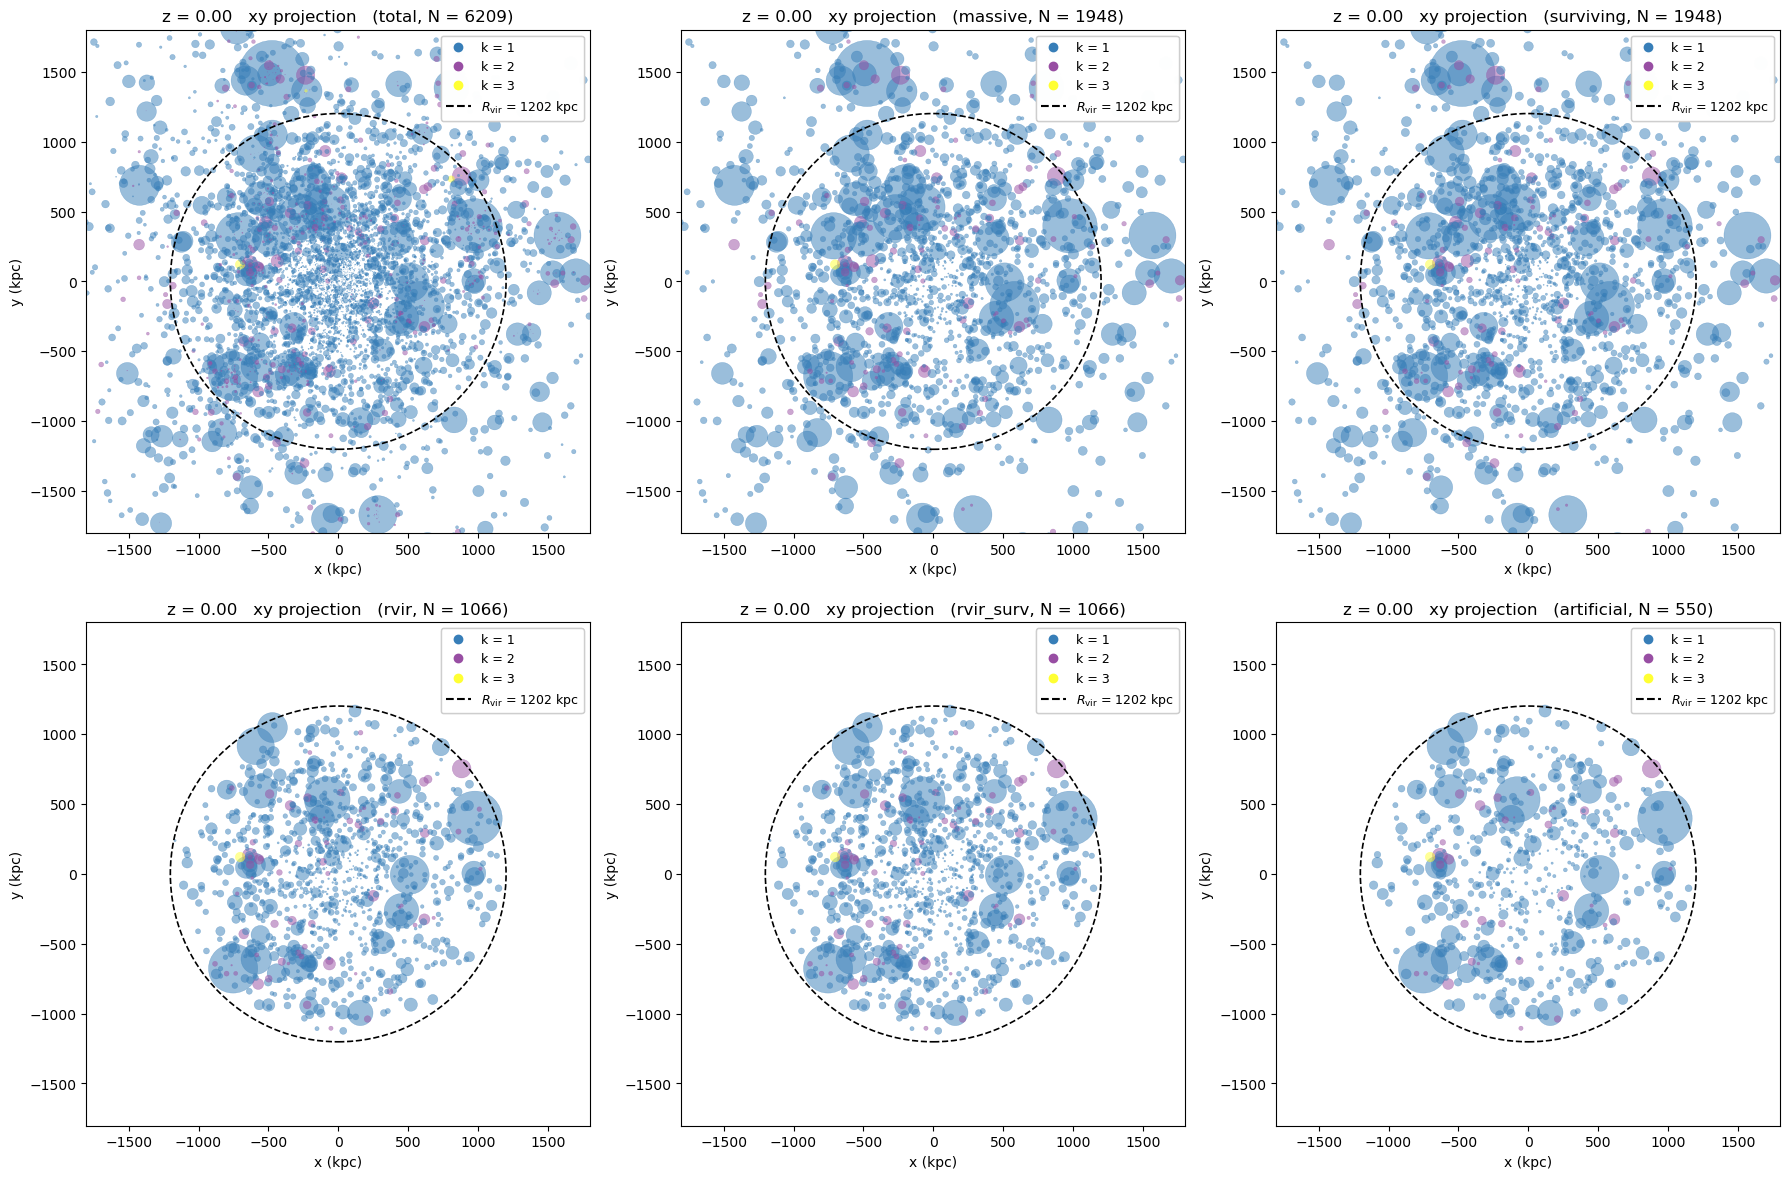

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for ax, regime in zip(axes.ravel(), tree.regime_masks):
    rt = tree.tidal_radius_history(tree.regime_masks[regime])[:, 0]
    tree.plot_subhalo_projection(rt=rt, proj='xy', iz=0, regime=regime, size_mode='physical', ax=ax)
plt.tight_layout()
plt.show()

## Movies

The movie cell below renders every regime in both size modes; trim `regimes` or `size_modes` to render fewer. `box='rvir'` rescales each frame to $R_{\rm vir}(t)$, and `stride` skips snapshots.

In [5]:
regimes = list(tree.regime_masks)     # all six
size_modes = ['physical', 'mass']
box, scale, stride, fps = 'fixed', 1.5, 1, 15

movie_dir = 'movies'
os.makedirs(movie_dir, exist_ok=True)
tree_name = os.path.basename(tree_file).replace('.npz', '')

videos = {}
for regime in regimes:
    for size_mode in size_modes:
        tag = 'rtidal' if size_mode == 'physical' else size_mode
        path = f'{movie_dir}/{tree_name}_positions_{regime}_{tag}.mp4'
        tree.make_projection_movie(path, regime=regime, size_mode=size_mode,
                                   box=box, scale=scale, stride=stride, fps=fps)
        videos[(regime, size_mode)] = path

wrote 300 frames to movies/tree_14.0_positions_total_rtidal.mp4
wrote 300 frames to movies/tree_14.0_positions_total_mass.mp4
wrote 299 frames to movies/tree_14.0_positions_massive_rtidal.mp4
wrote 299 frames to movies/tree_14.0_positions_massive_mass.mp4
wrote 209 frames to movies/tree_14.0_positions_surviving_rtidal.mp4
wrote 209 frames to movies/tree_14.0_positions_surviving_mass.mp4
wrote 299 frames to movies/tree_14.0_positions_rvir_rtidal.mp4
wrote 299 frames to movies/tree_14.0_positions_rvir_mass.mp4
wrote 208 frames to movies/tree_14.0_positions_rvir_surv_rtidal.mp4
wrote 208 frames to movies/tree_14.0_positions_rvir_surv_mass.mp4
wrote 182 frames to movies/tree_14.0_positions_artificial_rtidal.mp4
wrote 182 frames to movies/tree_14.0_positions_artificial_mass.mp4


In [6]:
for (regime, size_mode), path in videos.items():
    print(f'{regime} / {size_mode}')
    display(Video(path, width=960))

total / physical


total / mass


massive / physical


massive / mass


surviving / physical


surviving / mass


... (2 outputs left out)

rvir_surv / physical


rvir_surv / mass


artificial / physical


artificial / mass
